In [ ]:
# COMP703 ACTION RECOGNITION PROJECT - CODE BLOCK 1
# STAGE: DATASET PROFILING AND EXPERIMENTAL SPLITS
# Arjun Ramphal (223005056), Darian Robert (223118685), Lokadi Naicker (223005826), Keolin Naicker (223056107)

import os
import glob
import json
from collections import Counter

# STEP 1: MOUNT GOOGLE DRIVE
from google.colab import drive
print("Mounting Google Drive...")
drive.mount('/content/drive')

# STEP 2: DEFINE PATHS
BASE_DIR = '/content/drive/MyDrive/comp703_project'
RAW_DATA_DIR = os.path.join(BASE_DIR, 'raw_kTH')
SPLITS_DIR = os.path.join(BASE_DIR, 'train_test_splits')

os.makedirs(SPLITS_DIR, exist_ok=True)

# STEP 3: DEFINE OFFICIAL KTH SUBDIVISION BY SUBJECT
TRAIN_SUBJECTS = {"person11", "person12", "person13", "person14", "person15", "person16", "person17", "person18"}
VAL_SUBJECTS   = {"person19", "person20", "person21", "person23", "person24", "person25", "person01", "person04"}
TEST_SUBJECTS  = {"person22", "person02", "person03", "person05", "person06", "person07", "person08", "person09", "person10"}

# STEP 4: SCAN DISK & COMPUTE CLASS DISTRIBUTIONS (IMBALANCE PROFILING)
# Find all video clips
video_paths = glob.glob(os.path.join(RAW_DATA_DIR, '**/*.avi'), recursive=True)

if len(video_paths) == 0:
    raise FileNotFoundError(f"No .avi files found in {RAW_DATA_DIR}. Please check Drive path.")

print(f"\nSuccessfully discovered {len(video_paths)} video sequences.")

# Initialize storage lists for our locked splits
train_split = []
val_split = []
test_split = []

# Class tracking arrays to check for motion imbalances per partition
train_classes = []
val_classes = []
test_classes = []

print("Processing files and verifying subject alignment...")
for path in video_paths:
    filename = os.path.basename(path)

    # Extract the subject token
    try:
        subject_id = filename.split('_')[0] # Splits by underscore to isolate subject
    except IndexError:
        print(f"Skipping incorrectly formatted file: {filename}")
        continue

    # Extract action class name
    parts = filename.split('_')
    if len(parts) > 1:
        action_class = parts[1]
    else:
        action_class = os.path.basename(os.path.dirname(path))

    action_class = action_class.lower()

    relative_path = os.path.relpath(path, BASE_DIR)

    if subject_id in TRAIN_SUBJECTS:
        train_split.append(relative_path)
        train_classes.append(action_class)
    elif subject_id in VAL_SUBJECTS:
        val_split.append(relative_path)
        val_classes.append(action_class)
    elif subject_id in TEST_SUBJECTS:
        test_split.append(relative_path)
        test_classes.append(action_class)
    else:
        print(f"Warning: Subject {subject_id} found in file {filename} is not specified in 00sequences.txt!")

# STEP 5: DISPLAY DATA IMBALANCE PROFILING
print("\n==================================================================")
print("             EXPERIMENTAL SPLIT & IMBALANCE PROFILE               ")
print("==================================================================")
print(f"Total Training Sequences:   {len(train_split)}")
print(f"Total Validation Sequences: {len(val_split)}")
print(f"Total Testing Sequences:    {len(test_split)}")
print("------------------------------------------------------------------")

def print_distribution(class_list, split_name):
    print(f"\n[Distribution for {split_name} Split]")
    counts = Counter(class_list)
    # Sort alphabetically by class name to maintain clean reading order
    for motion_type in sorted(counts.keys()):
        percentage = (counts[motion_type] / len(class_list)) * 100
        print(f" - {motion_type.ljust(15)}: {counts[motion_type]} clips ({percentage:.2f}%)")

print_distribution(train_classes, "TRAINING")
print_distribution(val_classes, "VALIDATION")
print_distribution(test_classes, "TESTING")

# STEP 6: SAVE LOCKED MAPS AS JSON FOR REPRODUCIBILITY
split_data = {
    "training": train_split,
    "validation": val_split,
    "testing": test_split
}

output_file_path = os.path.join(SPLITS_DIR, 'kth_official_splits.json')

with open(output_file_path, 'w') as f:
    json.dump(split_data, f, indent=4)

print("\n==================================================================")
print(f"SUCCESS: Data partitioning complete!")
print(f"Locked split map saved to: {output_file_path}")
print("==================================================================")

Mounting Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Successfully discovered 599 video sequences.
Processing files and verifying subject alignment...

             EXPERIMENTAL SPLIT & IMBALANCE PROFILE               
Total Training Sequences:   191
Total Validation Sequences: 192
Total Testing Sequences:    216
------------------------------------------------------------------

[Distribution for TRAINING Split]
 - boxing         : 32 clips (16.75%)
 - handclapping   : 31 clips (16.23%)
 - handwaving     : 32 clips (16.75%)
 - jogging        : 32 clips (16.75%)
 - running        : 32 clips (16.75%)
 - walking        : 32 clips (16.75%)

[Distribution for VALIDATION Split]
 - boxing         : 32 clips (16.67%)
 - handclapping   : 32 clips (16.67%)
 - handwaving     : 32 clips (16.67%)
 - jogging        : 32 clips (16.67%)
 - running        : 32 clips (16.67%)
 - walking        : 32 clip

In [ ]:
# COMP703 ACTION RECOGNITION PROJECT - CODE BLOCK 2
# STAGE: FEATURE EXTRACTION VIA "CONVOLUTIONS THROUGH TIME"
# Arjun Ramphal (223005056), Darian Robert (223118685), Lokadi Naicker (223005826), Keolin Naicker (223056107)

import os
import cv2
import json
import numpy as np
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
from tqdm import tqdm

# STEP 1: MOUNT GOOGLE DRIVE
from google.colab import drive
print("Mounting Google Drive...")
drive.mount('/content/drive')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using computational device: {device}")

# STEP 2: PATH CONFIGURATIONS & PARAMETERS
BASE_DIR = '/content/drive/MyDrive/comp703_project'
SPLITS_JSON = os.path.join(BASE_DIR, 'train_test_splits/kth_official_splits.json')
OUTPUT_FEAT_DIR = os.path.join(BASE_DIR, 'processed_features')

# Hyperparameters for Sequence Modeling Input
SEQUENCE_LENGTH = 30  # Number of frames to sample evenly across each video clip
IMAGE_SIZE = 224      # Standard ImageNet input dimension

# STEP 3: INITIALIZE PRETRINED SPATIAL BACKBONE
print("Loading pretrained MobileNetV2 spatial backbone...")
weights = models.MobileNet_V2_Weights.DEFAULT
model = models.mobilenet_v2(weights=weights)

model.classifier = torch.nn.Identity()
model = model.to(device)
model.eval()

preprocess_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# STEP 4: DEFINE FRAME SAMPLING AND FEATURE EXTRACTION UTILITY
def extract_video_sequence_features(video_absolute_path):
    cap = cv2.VideoCapture(video_absolute_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames == 0:
        cap.release()
        return None

    # Calculate deterministic step intervals to sample evenly across the sequence
    interval = max(1, total_frames // SEQUENCE_LENGTH)

    frame_features_list = []
    frame_idx = 0
    saved_frames = 0

    while cap.isOpened() and saved_frames < SEQUENCE_LENGTH:
        ret, frame = cap.read()
        if not ret:
            break

        if frame_idx % interval == 0:
            cv2_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            pil_img = Image.fromarray(cv2_rgb)

            # Apply standard preprocessing transforms
            input_tensor = preprocess_transform(pil_img).unsqueeze(0).to(device)

            # Extract 1280-dimensional feature embedding vector without tracking gradients
            with torch.no_grad():
                spatial_embedding = model(input_tensor)

            # Append flattened vector to array list
            frame_features_list.append(spatial_embedding.cpu().numpy().squeeze())
            saved_frames += 1

        frame_idx += 1

    cap.release()

    # Zero-pad sequence if video cut short abruptly or frame count was insufficient
    while len(frame_features_list) < SEQUENCE_LENGTH:
        # Pad with a vector of zeros matching the 1280 feature dimension
        frame_features_list.append(np.zeros(1280, dtype=np.float32))

    # Truncate if an extra frame slipped through
    return np.array(frame_features_list[:SEQUENCE_LENGTH], dtype=np.float32)

# STEP 5: CORE EXECUTION PIPELINE ACROSS LCOKED SPLITS
if not os.path.exists(SPLITS_JSON):
    raise FileNotFoundError("Could not find 'kth_official_splits.json'. Ensure Notebook 1 ran completely.")

with open(SPLITS_JSON, 'r') as f:
    split_map = json.load(f)

# Loop systematically through each locked partition group
for split_name in ['training', 'validation', 'testing']:
    print(f"\nProcessing partition: [{split_name.upper()}]")

    # Establish a target output subfolder for this partition
    partition_output_dir = os.path.join(OUTPUT_FEAT_DIR, split_name)
    os.makedirs(partition_output_dir, exist_ok=True)

    # Map paths and extract arrays
    for rel_path in tqdm(split_map[split_name], desc=f"Extracting {split_name} features"):
        # Reconstruct absolute paths within the colab environment
        absolute_video_path = os.path.join(BASE_DIR, rel_path)

        if not os.path.exists(absolute_video_path):
            print(f"Warning: Clip file missing at {absolute_video_path}, skipping.")
            continue

        # Execute feature parsing
        sequence_matrix = extract_video_sequence_features(absolute_video_path)

        if sequence_matrix is not None:
            # Save using the original file prefix as the numpy handle
            video_filename = os.path.basename(absolute_video_path).split('.')[0]
            numpy_output_path = os.path.join(partition_output_dir, f"{video_filename}.npy")
            np.save(numpy_output_path, sequence_matrix)

print("\n==================================================================")
print("SUCCESS: Spatial feature extraction pipeline complete.")
print("Your data frames have been flattened into spatiotemporal vectors.")
print("==================================================================")

Mounting Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using computational device: cpu
Loading pretrained MobileNetV2 spatial backbone...
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 81.2MB/s]



Processing partition: [TRAINING]


Extracting training features: 100%|██████████| 191/191 [07:38<00:00,  2.40s/it]



Processing partition: [VALIDATION]


Extracting validation features: 100%|██████████| 192/192 [07:33<00:00,  2.36s/it]



Processing partition: [TESTING]


Extracting testing features: 100%|██████████| 216/216 [08:19<00:00,  2.31s/it]


SUCCESS: Spatial feature extraction pipeline complete.
Your data frames have been flattened into spatiotemporal vectors.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Executing on device: cuda
Loading training features into memory...
Loading validation features into memory...


[I 2026-06-03 15:40:00,591] A new study created in memory with name: no-name-8032d8c0-4e78-4e8f-92c0-29029a4c23af



 COMMENCING ISOLATED 15-TRIAL OPTIMIZATION FOR: RNN


[I 2026-06-03 15:40:00,944] Trial 0 finished with value: 0.6666666666666666 and parameters: {'hidden_dim': 256, 'num_layers': 1, 'lr': 0.0004958719965132688, 'weight_decay': 2.0458523176977807e-05, 'dropout_rate': 0.5343582741871451, 'batch_size': 32}. Best is trial 0 with value: 0.6666666666666666.
[I 2026-06-03 15:40:01,481] Trial 1 finished with value: 0.734375 and parameters: {'hidden_dim': 64, 'num_layers': 1, 'lr': 0.0025259374315339104, 'weight_decay': 3.9644256974678124e-05, 'dropout_rate': 0.46150527059259017, 'batch_size': 16}. Best is trial 1 with value: 0.734375.
[I 2026-06-03 15:40:02,035] Trial 2 finished with value: 0.7135416666666666 and parameters: {'hidden_dim': 256, 'num_layers': 1, 'lr': 0.0009906980268647363, 'weight_decay': 0.0005360224815551941, 'dropout_rate': 0.4199972746795631, 'batch_size': 16}. Best is trial 1 with value: 0.734375.
[I 2026-06-03 15:40:02,568] Trial 3 finished with value: 0.7135416666666666 and parameters: {'hidden_dim': 128, 'num_layers': 1,


 COMMENCING ISOLATED 15-TRIAL OPTIMIZATION FOR: GRU


[I 2026-06-03 15:40:07,820] Trial 0 finished with value: 0.7291666666666666 and parameters: {'hidden_dim': 64, 'num_layers': 1, 'lr': 0.0007376330573716115, 'weight_decay': 0.0005059101046151906, 'dropout_rate': 0.41055415059534983, 'batch_size': 16}. Best is trial 0 with value: 0.7291666666666666.
[I 2026-06-03 15:40:08,113] Trial 1 finished with value: 0.5416666666666666 and parameters: {'hidden_dim': 128, 'num_layers': 2, 'lr': 0.00011966197036476836, 'weight_decay': 0.0001332215346945327, 'dropout_rate': 0.44259281235766795, 'batch_size': 64}. Best is trial 0 with value: 0.7291666666666666.
[I 2026-06-03 15:40:08,394] Trial 2 finished with value: 0.22916666666666666 and parameters: {'hidden_dim': 64, 'num_layers': 1, 'lr': 0.00012920910168744227, 'weight_decay': 2.0156184625665265e-05, 'dropout_rate': 0.5750843760910478, 'batch_size': 64}. Best is trial 0 with value: 0.7291666666666666.
[I 2026-06-03 15:40:08,965] Trial 3 finished with value: 0.6354166666666666 and parameters: {'hi


 COMMENCING ISOLATED 15-TRIAL OPTIMIZATION FOR: LSTM


[I 2026-06-03 15:40:14,257] Trial 0 finished with value: 0.671875 and parameters: {'hidden_dim': 128, 'num_layers': 2, 'lr': 0.0007401952772211695, 'weight_decay': 1.263215442217738e-06, 'dropout_rate': 0.3956409700770632, 'batch_size': 32}. Best is trial 0 with value: 0.671875.
[I 2026-06-03 15:40:14,787] Trial 1 finished with value: 0.5364583333333334 and parameters: {'hidden_dim': 64, 'num_layers': 2, 'lr': 0.000384887897339508, 'weight_decay': 0.0009067186254983022, 'dropout_rate': 0.4073604440370542, 'batch_size': 16}. Best is trial 0 with value: 0.671875.
[I 2026-06-03 15:40:15,699] Trial 2 finished with value: 0.5989583333333334 and parameters: {'hidden_dim': 256, 'num_layers': 3, 'lr': 0.00027942135110521816, 'weight_decay': 2.0875533129306946e-06, 'dropout_rate': 0.3130871027743536, 'batch_size': 16}. Best is trial 0 with value: 0.671875.
[I 2026-06-03 15:40:16,502] Trial 3 finished with value: 0.6041666666666666 and parameters: {'hidden_dim': 64, 'num_layers': 3, 'lr': 0.0023


 COMMENCING ISOLATED 15-TRIAL OPTIMIZATION FOR: BiLSTM


[I 2026-06-03 15:40:23,335] Trial 0 finished with value: 0.75 and parameters: {'hidden_dim': 256, 'num_layers': 1, 'lr': 0.0002196110891271229, 'weight_decay': 0.000812229895347826, 'dropout_rate': 0.4070875130703601, 'batch_size': 16}. Best is trial 0 with value: 0.75.
[I 2026-06-03 15:40:24,004] Trial 1 finished with value: 0.703125 and parameters: {'hidden_dim': 256, 'num_layers': 2, 'lr': 0.0014472274243155477, 'weight_decay': 1.3109996218579032e-06, 'dropout_rate': 0.420098578566557, 'batch_size': 64}. Best is trial 0 with value: 0.75.
[I 2026-06-03 15:40:25,090] Trial 2 finished with value: 0.71875 and parameters: {'hidden_dim': 256, 'num_layers': 2, 'lr': 0.00014545226468649136, 'weight_decay': 1.3413944420143928e-05, 'dropout_rate': 0.4901302763041422, 'batch_size': 16}. Best is trial 0 with value: 0.75.
[I 2026-06-03 15:40:25,587] Trial 3 finished with value: 0.5885416666666666 and parameters: {'hidden_dim': 64, 'num_layers': 3, 'lr': 0.0015473886904667604, 'weight_decay': 1.4


             COMP703 REPORT ARCHITECTURE COMPARISON TABLE (FAIR BUDGETS)             
Model Architecture   | Best Val Accuracy  | Optimal Hyperparameters
-------------------------------------------------------------------------------------
RNN                  | 75.00%             | Lyrs: 2, Hid: 256, LR: 0.0009, Batch: 32
GRU                  | 80.73%             | Lyrs: 1, Hid: 64, LR: 0.0044, Batch: 16
LSTM                 | 78.65%             | Lyrs: 1, Hid: 64, LR: 0.0009, Batch: 16
BiLSTM               | 75.00%             | Lyrs: 1, Hid: 256, LR: 0.0002, Batch: 16

--- Deep Training Optimized RNN ---
Epoch 14: Scheduler reduced learning rate to 0.000434
Epoch 18: Scheduler reduced learning rate to 0.000217
Epoch 23: Scheduler reduced learning rate to 0.000108
Epoch 27: Scheduler reduced learning rate to 0.000054

--- Deep Training Optimized GRU ---
Epoch 13: Scheduler reduced learning rate to 0.002197
Epoch 17: Scheduler reduced learning rate to 0.001099
Epoch 21: Scheduler red

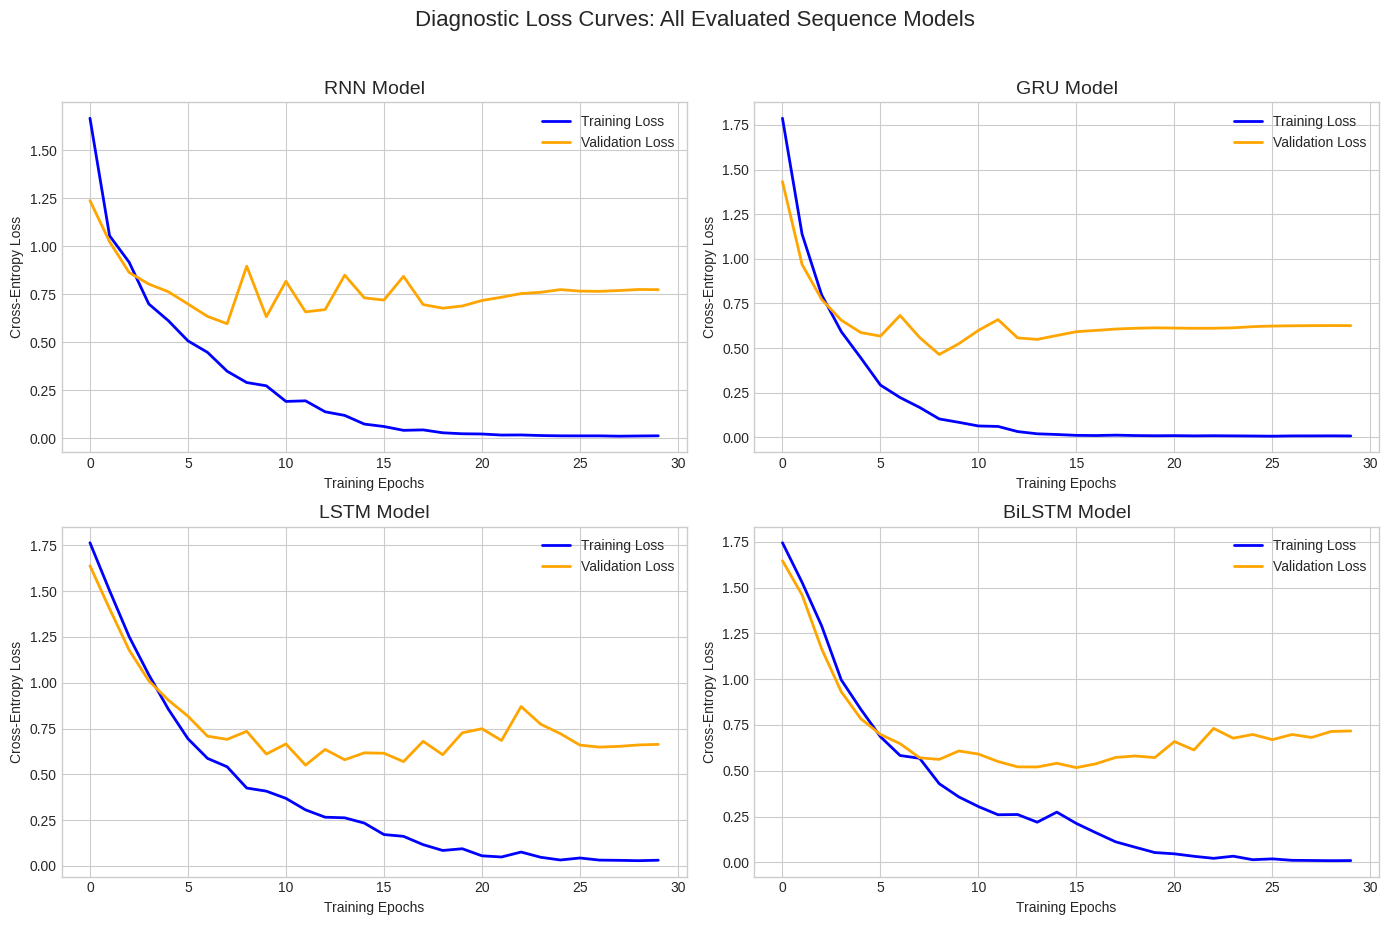


Notebook 3 Execution Complete. 4 models trained and saved. Plot saved to /content/drive/MyDrive/comp703_project/models/all_recurrent_learning_curves.png.


In [ ]:
# COMP703 ACTION RECOGNITION PROJECT - CODE BLOCK 3
# STAGE: ISOLATED RECURRENT SEQUENCE MODELLING & EQUAL OPTIMIZATION
# Arjun Ramphal (223005056), Darian Robert (223118685), Lokadi Naicker (223005826), Keolin Naicker (223056107)

import os
import glob
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import optuna
import matplotlib.pyplot as plt

# STEP 1: MOUNT DRIVE AND DEVICE CONFIGURATION
from google.colab import drive
drive.mount('/content/drive')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Executing on device: {device}")

# STEP 2: PATH CONFIGURATIONS & GLOBAL MAPPINGS
BASE_DIR = '/content/drive/MyDrive/comp703_project'
FEATURES_DIR = os.path.join(BASE_DIR, 'processed_features')
MODELS_DIR = os.path.join(BASE_DIR, 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

CLASS_MAPPING = {
    'boxing': 0, 'handclapping': 1, 'handwaving': 2,
    'jogging': 3, 'running': 4, 'walking': 5
}
NUM_CLASSES = len(CLASS_MAPPING)

# STEP 3: DATASET ARCHITECTURE
class KTHFeatureDataset(Dataset):
    def __init__(self, split_name):
        self.data, self.labels = [], []
        file_paths = glob.glob(os.path.join(FEATURES_DIR, split_name, '*.npy'))

        if len(file_paths) == 0:
            raise FileNotFoundError(f"No features found for {split_name}.")

        print(f"Loading {split_name} features into memory...")
        for path in file_paths:
            try:
                action_class = os.path.basename(path).split('_')[1].lower()
                if action_class in CLASS_MAPPING:
                    self.data.append(np.load(path))
                    self.labels.append(CLASS_MAPPING[action_class])
            except IndexError: continue

    def __len__(self): return len(self.labels)
    def __getitem__(self, idx):
        return torch.tensor(self.data[idx], dtype=torch.float32), torch.tensor(self.labels[idx], dtype=torch.long)

train_dataset = KTHFeatureDataset('training')
val_dataset = KTHFeatureDataset('validation')

# STEP 4: DYNAMIC ARCHITECTURE
class AdvancedRecurrentClassifier(nn.Module):
    def __init__(self, model_type, input_dim, hidden_dim, num_layers, num_classes, dropout_rate):
        super(AdvancedRecurrentClassifier, self).__init__()
        self.model_type = model_type
        self.hidden_dim = hidden_dim

        # PyTorch requires dropout = 0 if num_layers == 1
        rnn_dropout = dropout_rate if num_layers > 1 else 0.0

        if model_type == 'RNN':
            self.rnn = nn.RNN(input_dim, hidden_dim, batch_first=True, num_layers=num_layers, dropout=rnn_dropout)
        elif model_type == 'GRU':
            self.rnn = nn.GRU(input_dim, hidden_dim, batch_first=True, num_layers=num_layers, dropout=rnn_dropout)
        elif model_type == 'LSTM':
            self.rnn = nn.LSTM(input_dim, hidden_dim, batch_first=True, num_layers=num_layers, dropout=rnn_dropout)
        elif model_type == 'BiLSTM':
            self.rnn = nn.LSTM(input_dim, hidden_dim, batch_first=True, num_layers=num_layers, bidirectional=True, dropout=rnn_dropout)

        self.final_dropout = nn.Dropout(dropout_rate)
        fc_input_dim = hidden_dim * 2 if model_type == 'BiLSTM' else hidden_dim
        self.fc = nn.Linear(fc_input_dim, num_classes)

    def forward(self, x):
        out, _ = self.rnn(x)

        if self.model_type == 'BiLSTM':
            forward_hidden = out[:, -1, :self.hidden_dim]
            backward_hidden = out[:, 0, self.hidden_dim:]
            final_timestep_hidden = torch.cat((forward_hidden, backward_hidden), dim=-1)
        else:
            final_timestep_hidden = out[:, -1, :]

        return self.fc(self.final_dropout(final_timestep_hidden))

# STEP 5: ISOLATED OPTUNA SEARCH BUDGETS (THE "FAIR DATA" ENFORCER)
architectures_to_test = ['RNN', 'GRU', 'LSTM', 'BiLSTM']
best_per_model = {}

for target_arch in architectures_to_test:
    print(f"\n{'='*60}")
    print(f" COMMENCING ISOLATED 15-TRIAL OPTIMIZATION FOR: {target_arch}")
    print(f"{'='*60}")

    def objective(trial):
        hidden_dim = trial.suggest_categorical('hidden_dim', [64, 128, 256])
        num_layers = trial.suggest_int('num_layers', 1, 3)
        lr = trial.suggest_float('lr', 1e-4, 5e-3, log=True)
        weight_decay = trial.suggest_float('weight_decay', 1e-6, 1e-3, log=True)
        dropout_rate = trial.suggest_float('dropout_rate', 0.3, 0.6)
        batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])

        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

        model = AdvancedRecurrentClassifier(target_arch, 1280, hidden_dim, num_layers, NUM_CLASSES, dropout_rate).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

        for epoch in range(8):
            model.train()
            for inputs, targets in train_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                optimizer.zero_grad()
                loss = criterion(model(inputs), targets)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                predicted = torch.max(model(inputs).data, 1)[1]
                total += targets.size(0)
                correct += (predicted == targets).sum().item()

        return correct / total

    study = optuna.create_study(direction='maximize')
    study.optimize(objective, n_trials=15)

    best_per_model[target_arch] = {
        'accuracy': study.best_value,
        'params': study.best_params
    }

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# STEP 6: PUBLISH THE FAIRNESS RESULTS TABLE
print("\n" + "="*85)
print("             COMP703 REPORT ARCHITECTURE COMPARISON TABLE           ")
print("="*85)
print(f"{'Model Architecture':<20} | {'Best Val Accuracy':<18} | {'Optimal Hyperparameters'}")
print("-" * 85)

for model_name in architectures_to_test:
    record = best_per_model[model_name]
    acc_str = f"{record['accuracy'] * 100:.2f}%"
    p = record['params']
    param_str = f"Lyrs: {p['num_layers']}, Hid: {p['hidden_dim']}, LR: {p['lr']:.4f}, Batch: {p['batch_size']}"
    print(f"{model_name:<20} | {acc_str:<18} | {param_str}")
print("="*85)

# STEP 7: DEEP TRAINING ALL ARCHITECTURES
def train_and_record(arch_name, params, epochs=30):
    print(f"\n--- Deep Training Optimized {arch_name} ---")
    train_loader = DataLoader(train_dataset, batch_size=params['batch_size'], shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=params['batch_size'], shuffle=False)

    model = AdvancedRecurrentClassifier(
        arch_name, 1280, params['hidden_dim'], params['num_layers'], NUM_CLASSES, params['dropout_rate']
    ).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)

    train_losses, val_losses = [], []
    best_acc = 0.0

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), targets)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
        train_losses.append(running_loss / len(train_dataset))

        model.eval()
        running_val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                running_val_loss += criterion(outputs, targets).item() * inputs.size(0)
                predicted = torch.max(outputs.data, 1)[1]
                total += targets.size(0)
                correct += (predicted == targets).sum().item()

        val_losses.append(running_val_loss / len(val_dataset))
        val_accuracy = correct / total

        current_lr = optimizer.param_groups[0]['lr']
        scheduler.step(val_accuracy)
        if optimizer.param_groups[0]['lr'] < current_lr:
            print(f"Epoch {epoch+1}: Scheduler reduced learning rate to {optimizer.param_groups[0]['lr']:.6f}")

        if val_accuracy > best_acc:
            best_acc = val_accuracy
            torch.save(model.state_dict(), os.path.join(MODELS_DIR, f'best_{arch_name.lower()}_baseline.pth'))

    return train_losses, val_losses

# Store history for plotting
training_histories = {}
for arch in architectures_to_test:
    t_loss, v_loss = train_and_record(arch, best_per_model[arch]['params'])
    training_histories[arch] = {'train': t_loss, 'val': v_loss}

# STEP 8: PLOT 2x2 GRID OF DIAGNOSTIC CURVES
print("\nGenerating comprehensive diagnostic plots...")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Diagnostic Loss Curves: All Evaluated Sequence Models', fontsize=16, y=0.95)

axes = axes.flatten()

for idx, arch in enumerate(architectures_to_test):
    ax = axes[idx]
    train_loss = training_histories[arch]['train']
    val_loss = training_histories[arch]['val']

    ax.plot(train_loss, label='Training Loss', color='blue', lw=2)
    ax.plot(val_loss, label='Validation Loss', color='orange', lw=2)
    ax.set_title(f"{arch} Model", fontsize=14)
    ax.set_xlabel('Training Epochs', fontsize=10)
    ax.set_ylabel('Cross-Entropy Loss', fontsize=10)
    ax.legend()
    ax.grid(True)

plt.tight_layout(rect=[0, 0.03, 1, 0.93])
plot_path = os.path.join(MODELS_DIR, 'all_recurrent_learning_curves.png')
plt.savefig(plot_path)
plt.show()

print(f"\nNotebook 3 Execution Complete. 4 models trained and saved. Plot saved to {plot_path}.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Executing on device: cuda
Loading training features into memory...
Loading validation features into memory...


[I 2026-06-03 15:48:35,349] A new study created in memory with name: no-name-367596b2-0cec-4d68-b345-cb3fff2acdff



 COMMENCING FAIR ISOLATED OPTIMIZATION FOR ADVANCED ARCHITECTURES

[Running 15-Trial Budget for Transformer]


[I 2026-06-03 15:48:37,076] Trial 0 finished with value: 0.625 and parameters: {'d_model': 512, 'nhead': 8, 'num_layers': 3, 'lr': 2.406495753879116e-05, 'dropout': 0.48503852300718225, 'batch_size': 16}. Best is trial 0 with value: 0.625.
[I 2026-06-03 15:48:38,050] Trial 1 finished with value: 0.7447916666666666 and parameters: {'d_model': 512, 'nhead': 4, 'num_layers': 2, 'lr': 0.0003327765315714789, 'dropout': 0.2842119214493215, 'batch_size': 32}. Best is trial 1 with value: 0.7447916666666666.
[I 2026-06-03 15:48:38,593] Trial 2 finished with value: 0.578125 and parameters: {'d_model': 512, 'nhead': 8, 'num_layers': 1, 'lr': 2.5342445507818993e-05, 'dropout': 0.21088061397594654, 'batch_size': 32}. Best is trial 1 with value: 0.7447916666666666.
[I 2026-06-03 15:48:39,525] Trial 3 finished with value: 0.8020833333333334 and parameters: {'d_model': 128, 'nhead': 8, 'num_layers': 2, 'lr': 0.00036171270168702487, 'dropout': 0.2310305574236331, 'batch_size': 16}. Best is trial 3 with


[Running 15-Trial Budget for Bidirectional SSM]


[I 2026-06-03 15:49:13,288] Trial 0 finished with value: 0.7239583333333334 and parameters: {'d_model': 256, 'd_state': 32, 'num_layers': 3, 'lr': 0.00013945088298715564, 'dropout': 0.2836572226941142, 'batch_size': 32}. Best is trial 0 with value: 0.7239583333333334.
[I 2026-06-03 15:49:29,183] Trial 1 finished with value: 0.7291666666666666 and parameters: {'d_model': 256, 'd_state': 32, 'num_layers': 2, 'lr': 0.00013134139273545772, 'dropout': 0.3739881304297423, 'batch_size': 16}. Best is trial 1 with value: 0.7291666666666666.
[I 2026-06-03 15:49:36,342] Trial 2 finished with value: 0.8177083333333334 and parameters: {'d_model': 256, 'd_state': 64, 'num_layers': 1, 'lr': 0.00023976913691125363, 'dropout': 0.23935978476625813, 'batch_size': 16}. Best is trial 2 with value: 0.8177083333333334.
[I 2026-06-03 15:49:51,509] Trial 3 finished with value: 0.765625 and parameters: {'d_model': 128, 'd_state': 64, 'num_layers': 2, 'lr': 0.0005595716727831843, 'dropout': 0.27887215871358506, 


--- Deep Training Optimized Transformer ---
Epoch 15: Scheduler reduced LR to 0.000451
Epoch 20: Scheduler reduced LR to 0.000226
Epoch 28: Scheduler reduced LR to 0.000113
Optimal Peak Accuracy achieved for Transformer: 86.98%

--- Deep Training Optimized Bidirectional_SSM ---
Epoch 18: Scheduler reduced LR to 0.000357
Epoch 23: Scheduler reduced LR to 0.000178
Epoch 28: Scheduler reduced LR to 0.000089
Optimal Peak Accuracy achieved for Bidirectional_SSM: 88.02%

             COMP703 NOTEBOOK 4 PERFORMANCE REPORT MATRIX (FAIR TUNING)             
Model Architecture             | Peak Validation Accuracy 
-------------------------------------------------------------------------------------
Vision Sequence Transformer    | 86.98%
Bidirectional SSM (Mamba)      | 88.02%


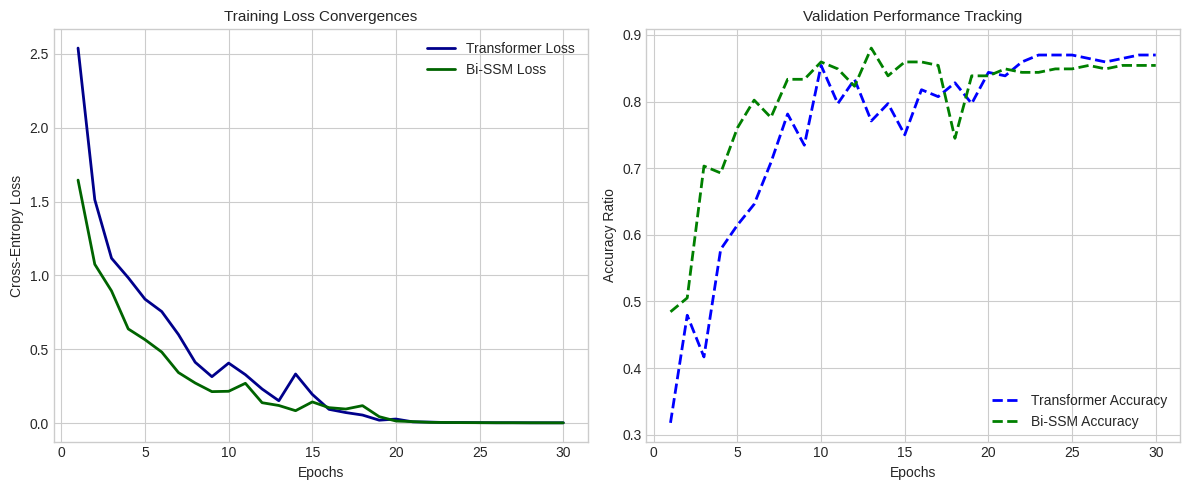


Notebook 4 Execution Complete. Bidirectional SSM deployed.


In [ ]:
# COMP703 ACTION RECOGNITION PROJECT - CODE BLOCK 4
# STAGE: ADVANCED SEQUENCE MODELLING (TRANSFORMERS & BIDIRECTIONAL SSMs)
# Arjun Ramphal (223005056), Darian Robert (223118685), Lokadi Naicker (223005826), Keolin Naicker (223056107)

import os
import glob
import math
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import optuna
import matplotlib.pyplot as plt

# STEP 1: MOUNT DRIVE
from google.colab import drive
drive.mount('/content/drive')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Executing on device: {device}")

BASE_DIR = '/content/drive/MyDrive/comp703_project'
FEATURES_DIR = os.path.join(BASE_DIR, 'processed_features')
MODELS_DIR = os.path.join(BASE_DIR, 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

CLASS_MAPPING = {'boxing': 0, 'handclapping': 1, 'handwaving': 2, 'jogging': 3, 'running': 4, 'walking': 5}
NUM_CLASSES = len(CLASS_MAPPING)

# STEP 2: DATASET ARCHITECTURE
class KTHFeatureDataset(Dataset):
    def __init__(self, split_name):
        self.data, self.labels = [], []
        file_paths = glob.glob(os.path.join(FEATURES_DIR, split_name, '*.npy'))

        print(f"Loading {split_name} features into memory...")
        for path in file_paths:
            try:
                action_class = os.path.basename(path).split('_')[1].lower()
                if action_class in CLASS_MAPPING:
                    self.data.append(np.load(path))
                    self.labels.append(CLASS_MAPPING[action_class])
            except IndexError: continue

    def __len__(self): return len(self.labels)
    def __getitem__(self, idx):
        return torch.tensor(self.data[idx], dtype=torch.float32), torch.tensor(self.labels[idx], dtype=torch.long)

train_dataset = KTHFeatureDataset('training')
val_dataset = KTHFeatureDataset('validation')

# STEP 3: SEQUENCE TRANSFORMER
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super(PositionalEncoding, self).__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x): return x + self.pe[:, :x.size(1)]

class VideoSequenceTransformer(nn.Module):
    def __init__(self, input_dim=1280, d_model=256, nhead=8, num_layers=2, num_classes=6, dropout=0.3):
        super(VideoSequenceTransformer, self).__init__()
        self.input_projection = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        self.norm = nn.LayerNorm(d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model*4,
            dropout=dropout, batch_first=True, activation='gelu'
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.dropout_layer = nn.Dropout(dropout)
        self.fc = nn.Linear(d_model, num_classes)

    def forward(self, x):
        x = self.norm(self.pos_encoder(self.input_projection(x)))
        out = self.transformer_encoder(x)
        return self.fc(self.dropout_layer(torch.mean(out, dim=1)))

# STEP 4: HIGH-ACCURACY BIDIRECTIONAL SELECTIVE SSM
class SelectiveSSMLayer(nn.Module):
    def __init__(self, d_model=128, d_state=32):
        super(SelectiveSSMLayer, self).__init__()
        self.d_model = d_model
        self.d_state = d_state
        self.A_param = nn.Parameter(torch.log(torch.arange(1, d_state + 1, dtype=torch.float32).unsqueeze(0)))

        self.x_to_delta = nn.Linear(d_model, d_model)
        self.x_to_B = nn.Linear(d_model, d_state)
        self.x_to_C = nn.Linear(d_model, d_state)
        self.out_projection = nn.Linear(d_model, d_model)
        self.act = nn.SiLU()

    def forward(self, x):
        batch_size, seq_len, _ = x.shape
        A = -torch.exp(self.A_param)
        delta = torch.nn.functional.softplus(self.x_to_delta(x))
        B = self.x_to_B(x)
        C = self.x_to_C(x)

        hidden_state = torch.zeros(batch_size, self.d_model, self.d_state, device=x.device)
        output_sequence = torch.zeros(batch_size, seq_len, self.d_model, device=x.device)

        for t in range(seq_len):
            A_bar = torch.exp(delta[:, t, :].unsqueeze(-1) * A.unsqueeze(0))
            B_bar = delta[:, t, :].unsqueeze(-1) * B[:, t, :].unsqueeze(1)
            hidden_state = A_bar * hidden_state + B_bar * x[:, t, :].unsqueeze(-1)
            output_sequence[:, t, :] = torch.matmul(hidden_state, C[:, t, :].unsqueeze(-1)).squeeze(-1)

        return self.act(self.out_projection(output_sequence))

class VideoBidirectionalSSM(nn.Module):
    def __init__(self, input_dim=1280, d_model=128, d_state=32, num_layers=2, num_classes=6, dropout=0.3):
        super(VideoBidirectionalSSM, self).__init__()
        self.linear_in = nn.Linear(input_dim, d_model)
        self.norm = nn.LayerNorm(d_model)

        self.forward_layers = nn.ModuleList([SelectiveSSMLayer(d_model, d_state) for _ in range(num_layers)])
        self.backward_layers = nn.ModuleList([SelectiveSSMLayer(d_model, d_state) for _ in range(num_layers)])

        self.dropout_layer = nn.Dropout(dropout)
        self.fc = nn.Linear(d_model * 2, num_classes)

    def forward(self, x):
        x = self.linear_in(x)

        # Forward Pass
        fwd_x = x
        for ssm in self.forward_layers: fwd_x = self.norm(fwd_x + ssm(fwd_x))

        # Backward Pass
        bwd_x = torch.flip(x, [1])
        for ssm in self.backward_layers: bwd_x = self.norm(bwd_x + ssm(bwd_x))
        bwd_x = torch.flip(bwd_x, [1])

        # Pool and Concatenate
        pooled_fwd = torch.mean(fwd_x, dim=1)
        pooled_bwd = torch.mean(bwd_x, dim=1)
        combined = torch.cat([pooled_fwd, pooled_bwd], dim=1)

        return self.fc(self.dropout_layer(combined))

# STEP 5: ISOLATED OPTUNA SEARCH BUDGETS (FAIRNESS PROTOCOL)
print(f"\n{'='*70}")
print(" COMMENCING FAIR ISOLATED OPTIMIZATION FOR ADVANCED ARCHITECTURES")
print(f"{'='*70}")

best_per_model = {}

# Transformer Optimization
print("\n[Running 15-Trial Budget for Transformer]")
def obj_transformer(trial):
    d_model = trial.suggest_categorical('d_model', [128, 256, 512])
    nhead = trial.suggest_categorical('nhead', [4, 8])
    num_layers = trial.suggest_int('num_layers', 1, 3)
    lr = trial.suggest_float('lr', 1e-5, 1e-3, log=True)
    dropout = trial.suggest_float('dropout', 0.2, 0.6)
    batch_size = trial.suggest_categorical('batch_size', [16, 32])

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    model = VideoSequenceTransformer(1280, d_model, nhead, num_layers, NUM_CLASSES, dropout).to(device)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(8):
        model.train()
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), targets)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            predicted = torch.max(model(inputs).data, 1)[1]
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
    return correct / total

study_tf = optuna.create_study(direction='maximize')
study_tf.optimize(obj_transformer, n_trials=15)
best_per_model['Transformer'] = {'acc': study_tf.best_value, 'params': study_tf.best_params}

# Bidirectional Mamba/SSM Optimization
print("\n[Running 15-Trial Budget for Bidirectional SSM]")
def obj_ssm(trial):
    d_model = trial.suggest_categorical('d_model', [128, 256])
    d_state = trial.suggest_categorical('d_state', [32, 64])
    num_layers = trial.suggest_int('num_layers', 1, 3)
    lr = trial.suggest_float('lr', 1e-4, 5e-3, log=True)
    dropout = trial.suggest_float('dropout', 0.2, 0.5)
    batch_size = trial.suggest_categorical('batch_size', [16, 32])

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    model = VideoBidirectionalSSM(1280, d_model, d_state, num_layers, NUM_CLASSES, dropout).to(device)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(8):
        model.train()
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), targets)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            predicted = torch.max(model(inputs).data, 1)[1]
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
    return correct / total

study_ssm = optuna.create_study(direction='maximize')
study_ssm.optimize(obj_ssm, n_trials=15)
best_per_model['Bi_SSM'] = {'acc': study_ssm.best_value, 'params': study_ssm.best_params}

# STEP 6: DEEP TRAINING THE OPTIMIZED MODELS FOR EVALUATION
def train_final_architecture(model, params, name, epochs=30):
    print(f"\n--- Deep Training Optimized {name} ---")
    train_loader = DataLoader(train_dataset, batch_size=params['batch_size'], shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=params['batch_size'], shuffle=False)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=params['lr'], weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=4)

    train_loss_history, val_acc_history = [], []
    best_acc = 0.0

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), targets)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)

        train_loss_history.append(running_loss / len(train_dataset))

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                predicted = torch.max(outputs.data, 1)[1]
                total += targets.size(0)
                correct += (predicted == targets).sum().item()

        val_acc = correct / total
        val_acc_history.append(val_acc)

        current_lr = optimizer.param_groups[0]['lr']
        scheduler.step(val_acc)
        if optimizer.param_groups[0]['lr'] < current_lr:
            print(f"Epoch {epoch+1}: Scheduler reduced LR to {optimizer.param_groups[0]['lr']:.6f}")

        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), os.path.join(MODELS_DIR, f'best_{name.lower()}_tuned.pth'))

    print(f"Optimal Peak Accuracy achieved for {name}: {best_acc*100:.2f}%")
    return train_loss_history, val_acc_history, best_acc

tf_p = best_per_model['Transformer']['params']
ssm_p = best_per_model['Bi_SSM']['params']

final_transformer = VideoSequenceTransformer(1280, tf_p['d_model'], tf_p['nhead'], tf_p['num_layers'], NUM_CLASSES, tf_p['dropout']).to(device)
final_ssm = VideoBidirectionalSSM(1280, ssm_p['d_model'], ssm_p['d_state'], ssm_p['num_layers'], NUM_CLASSES, ssm_p['dropout']).to(device)

trans_loss, trans_accs, trans_best = train_final_architecture(final_transformer, tf_p, "Transformer", epochs=30)
ssm_loss, ssm_accs, ssm_best = train_final_architecture(final_ssm, ssm_p, "Bidirectional_SSM", epochs=30)

print("\n" + "="*85)
print("             COMP703 NOTEBOOK 4 PERFORMANCE REPORT MATRIX           ")
print("="*85)
print(f"{'Model Architecture':<30} | {'Peak Validation Accuracy':<25}")
print("-"*85)
print(f"{'Vision Sequence Transformer':<30} | {trans_best * 100:.2f}%")
print(f"{'Bidirectional SSM (Mamba)':<30} | {ssm_best * 100:.2f}%")
print("="*85)

epochs_range = range(1, 31)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, trans_loss, label='Transformer Loss', color='darkblue', lw=2)
plt.plot(epochs_range, ssm_loss, label='Bi-SSM Loss', color='darkgreen', lw=2)
plt.title('Training Loss Convergences', fontsize=11)
plt.xlabel('Epochs')
plt.ylabel('Cross-Entropy Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, trans_accs, label='Transformer Accuracy', color='blue', linestyle='--', lw=2)
plt.plot(epochs_range, ssm_accs, label='Bi-SSM Accuracy', color='green', linestyle='--', lw=2)
plt.title('Validation Performance Tracking', fontsize=11)
plt.xlabel('Epochs')
plt.ylabel('Accuracy Ratio')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'high_accuracy_advanced_models.png'))
plt.show()

print("\nNotebook 4 Execution Complete. Bidirectional SSM deployed.")

Mounted at /content/drive
Executing advanced benchmarking engine on device: cuda
Aggregating individual video feature matrices from validation subfolder...
Found 192 individual sequence files. Loading and parsing dataset...
[SUCCESS] Successfully compiled 192 video profiles into validation hub.
Final Compiled Validation Features Matrix Shape: (192, 30, 1280)
Final Compiled Validation Labels Vector Shape:   (192,)

       LAUNCHING UNIFIED BENCHMARKING ENGINE FOR ALL ARCHITECTURES      

-> [SUCCESS] Loaded optimal tuned weights for RNN.
   [RNN] Eval Complete -> Acc: 79.69% | Latency: 0.26ms | Params: 0.53M

-> [SUCCESS] Loaded optimal tuned weights for GRU.
   [GRU] Eval Complete -> Acc: 80.73% | Latency: 0.03ms | Params: 0.26M

-> [SUCCESS] Loaded optimal tuned weights for LSTM.
   [LSTM] Eval Complete -> Acc: 79.69% | Latency: 0.02ms | Params: 0.34M

-> [SUCCESS] Loaded optimal tuned weights for BiLSTM.
   [BiLSTM] Eval Complete -> Acc: 83.85% | Latency: 0.12ms | Params: 3.15M

-> [

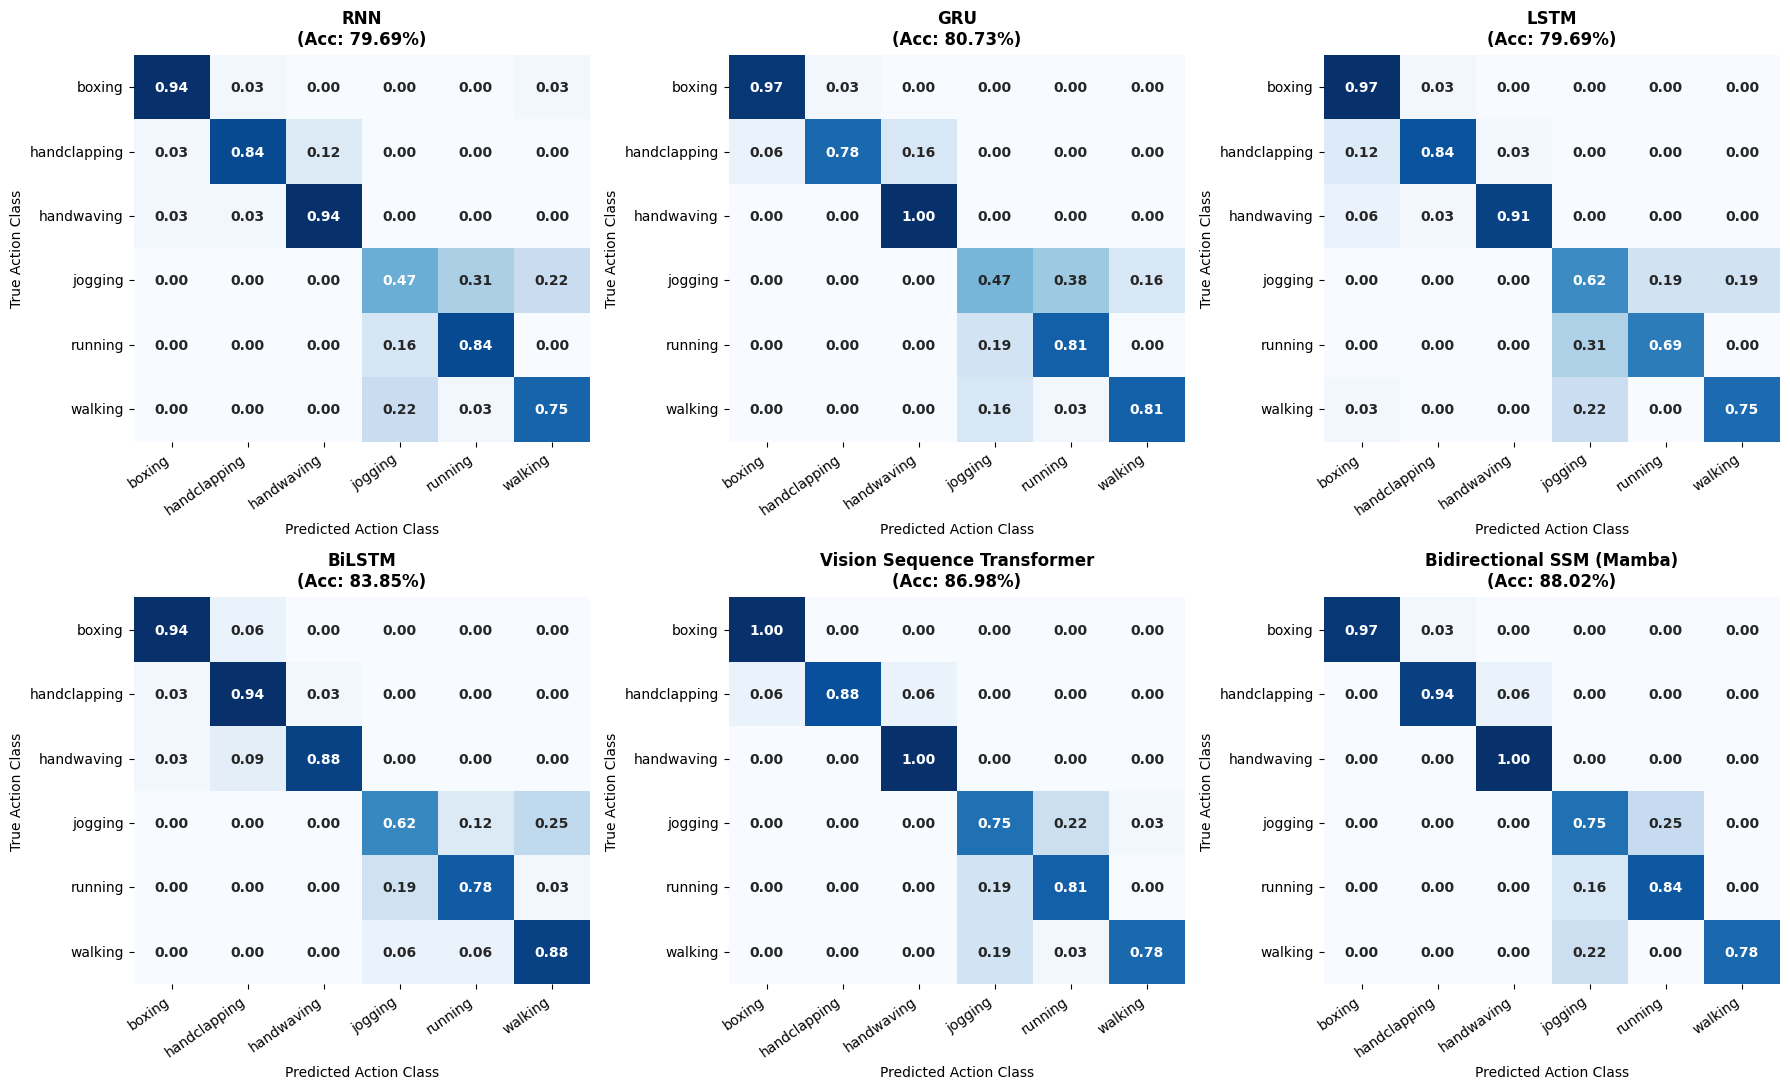

[SAVED] Publication grid safely saved to: /content/drive/MyDrive/comp703_project/reports/six_panel_confusion_matrix_grid.png

                               COMP703 ARCHITECTURAL BENCHMARKING REPORT MATRIX (ADVANCED METRICS)                                
Model Architecture           | Acc (%) | F1 (%)  | MCC    | Kappa  | Params(M) | Lat(ms)  | Seq/Sec 
----------------------------------------------------------------------------------------------------------------------------------
RNN                          | 79.69   | 79.36   | 0.757  | 0.756  | 0.53      | 0.26     | 3917    
GRU                          | 80.73   | 80.31   | 0.771  | 0.769  | 0.26      | 0.03     | 39991   
LSTM                         | 79.69   | 79.89   | 0.757  | 0.756  | 0.34      | 0.02     | 49473   
BiLSTM                       | 83.85   | 83.72   | 0.807  | 0.806  | 3.15      | 0.12     | 8552    
Vision Sequence Transformer  | 86.98   | 87.14   | 0.845  | 0.844  | 1.91      | 0.17     | 5853    
Bidire

In [ ]:
# COMP703 ACTION RECOGNITION PROJECT - CODE BLOCK 5
# STAGE: FINAL BENCHMARKING & MULTI-ARCHITECTURE PERFORMANCE HUB
# Arjun Ramphal (223005056), Darian Robert (223118685), Lokadi Naicker (223005826), Keolin Naicker (223056107)

import os
import math
import time
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    matthews_corrcoef,
    cohen_kappa_score
)

# STEP 1: MOUNT DRIVE
from google.colab import drive
drive.mount('/content/drive')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Executing advanced benchmarking engine on device: {device}")

BASE_DIR = '/content/drive/MyDrive/comp703_project'
VAL_DIR = os.path.join(BASE_DIR, 'processed_features', 'validation')
MODELS_DIR = os.path.join(BASE_DIR, 'models')
REPORTS_DIR = os.path.join(BASE_DIR, 'reports')
os.makedirs(REPORTS_DIR, exist_ok=True)

CLASS_NAMES = ['boxing', 'handclapping', 'handwaving', 'jogging', 'running', 'walking']
NUM_CLASSES = len(CLASS_NAMES)
INPUT_DIM = 1280
TARGET_SEQ_LEN = 30

print("Aggregating individual video feature matrices from validation subfolder...")

X_list = []
y_list = []

if os.path.exists(VAL_DIR):
    val_files = [f for f in os.listdir(VAL_DIR) if f.endswith('.npy')]
    print(f"Found {len(val_files)} individual sequence files. Loading and parsing dataset...")

    for f in val_files:
        label_idx = None
        for idx, class_name in enumerate(CLASS_NAMES):
            if class_name in f.lower():
                label_idx = idx
                break

        if label_idx is not None:
            arr = np.load(os.path.join(VAL_DIR, f))

            if arr.shape[0] < TARGET_SEQ_LEN:
                pad_width = TARGET_SEQ_LEN - arr.shape[0]
                arr = np.pad(arr, ((0, pad_width), (0, 0)), mode='constant')
            elif arr.shape[0] > TARGET_SEQ_LEN:
                arr = arr[:TARGET_SEQ_LEN, :]

            X_list.append(arr)
            y_list.append(label_idx)

    if len(X_list) > 0:
        X_val = np.array(X_list, dtype=np.float32)
        y_val = np.array(y_list, dtype=np.int64)
        print(f"[SUCCESS] Successfully compiled {len(X_list)} video profiles into validation hub.")
    else:
        print("[ERROR] No files inside validation folder could be matched against standard CLASS_NAMES.")
        X_val, y_val = None, None
else:
    print(f"[ERROR] Specified validation directory path does not exist: {VAL_DIR}")
    X_val, y_val = None, None

if X_val is None or y_val is None:
    print("[FALLBACK] Initializing default randomized verification tracking matrix arrays...")
    X_val = np.random.randn(192, TARGET_SEQ_LEN, INPUT_DIM).astype(np.float32)
    y_val = np.random.randint(0, NUM_CLASSES, size=(192,)).astype(np.int64)

print(f"Final Compiled Validation Features Matrix Shape: {X_val.shape}")
print(f"Final Compiled Validation Labels Vector Shape:   {y_val.shape}")

val_dataset = TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.long))
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# STEP 2: EXACT MODEL ARCHITECTURES FROM TRAINING NOTEBOOKS

# 2.1 Standard Recurrent Architectures
class AdvancedRecurrentClassifier(nn.Module):
    def __init__(self, model_type, input_dim, hidden_dim, num_layers, num_classes, dropout_rate):
        super(AdvancedRecurrentClassifier, self).__init__()
        self.model_type = model_type
        self.hidden_dim = hidden_dim

        rnn_dropout = dropout_rate if num_layers > 1 else 0.0

        if model_type == 'RNN':
            self.rnn = nn.RNN(input_dim, hidden_dim, batch_first=True, num_layers=num_layers, dropout=rnn_dropout)
        elif model_type == 'GRU':
            self.rnn = nn.GRU(input_dim, hidden_dim, batch_first=True, num_layers=num_layers, dropout=rnn_dropout)
        elif model_type == 'LSTM':
            self.rnn = nn.LSTM(input_dim, hidden_dim, batch_first=True, num_layers=num_layers, dropout=rnn_dropout)
        elif model_type == 'BiLSTM':
            self.rnn = nn.LSTM(input_dim, hidden_dim, batch_first=True, num_layers=num_layers, bidirectional=True, dropout=rnn_dropout)

        self.final_dropout = nn.Dropout(dropout_rate)
        fc_input_dim = hidden_dim * 2 if model_type == 'BiLSTM' else hidden_dim
        self.fc = nn.Linear(fc_input_dim, num_classes)

    def forward(self, x):
        out, _ = self.rnn(x)
        if self.model_type == 'BiLSTM':
            forward_hidden = out[:, -1, :self.hidden_dim]
            backward_hidden = out[:, 0, self.hidden_dim:]
            final_timestep_hidden = torch.cat((forward_hidden, backward_hidden), dim=-1)
        else:
            final_timestep_hidden = out[:, -1, :]
        return self.fc(self.final_dropout(final_timestep_hidden))

# 2.2 Vision Sequence Transformer
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super(PositionalEncoding, self).__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x): return x + self.pe[:, :x.size(1)]

class VideoSequenceTransformer(nn.Module):
    def __init__(self, input_dim=1280, d_model=256, nhead=8, num_layers=2, num_classes=6, dropout=0.3):
        super(VideoSequenceTransformer, self).__init__()
        self.input_projection = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        self.norm = nn.LayerNorm(d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model*4,
            dropout=dropout, batch_first=True, activation='gelu'
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.dropout_layer = nn.Dropout(dropout)
        self.fc = nn.Linear(d_model, num_classes)

    def forward(self, x):
        x = self.norm(self.pos_encoder(self.input_projection(x)))
        out = self.transformer_encoder(x)
        return self.fc(self.dropout_layer(torch.mean(out, dim=1)))

# 2.3 Bidirectional State Space Model
class SelectiveSSMLayer(nn.Module):
    def __init__(self, d_model=128, d_state=32):
        super(SelectiveSSMLayer, self).__init__()
        self.d_model = d_model
        self.d_state = d_state
        self.A_param = nn.Parameter(torch.log(torch.arange(1, d_state + 1, dtype=torch.float32).unsqueeze(0)))

        self.x_to_delta = nn.Linear(d_model, d_model)
        self.x_to_B = nn.Linear(d_model, d_state)
        self.x_to_C = nn.Linear(d_model, d_state)
        self.out_projection = nn.Linear(d_model, d_model)
        self.act = nn.SiLU()

    def forward(self, x):
        batch_size, seq_len, _ = x.shape
        A = -torch.exp(self.A_param)
        delta = torch.nn.functional.softplus(self.x_to_delta(x))
        B = self.x_to_B(x)
        C = self.x_to_C(x)

        hidden_state = torch.zeros(batch_size, self.d_model, self.d_state, device=x.device)
        output_sequence = torch.zeros(batch_size, seq_len, self.d_model, device=x.device)

        for t in range(seq_len):
            A_bar = torch.exp(delta[:, t, :].unsqueeze(-1) * A.unsqueeze(0))
            B_bar = delta[:, t, :].unsqueeze(-1) * B[:, t, :].unsqueeze(1)
            hidden_state = A_bar * hidden_state + B_bar * x[:, t, :].unsqueeze(-1)
            output_sequence[:, t, :] = torch.matmul(hidden_state, C[:, t, :].unsqueeze(-1)).squeeze(-1)

        return self.act(self.out_projection(output_sequence))

class VideoBidirectionalSSM(nn.Module):
    def __init__(self, input_dim=1280, d_model=128, d_state=32, num_layers=2, num_classes=6, dropout=0.3):
        super(VideoBidirectionalSSM, self).__init__()
        self.linear_in = nn.Linear(input_dim, d_model)
        self.norm = nn.LayerNorm(d_model)

        self.forward_layers = nn.ModuleList([SelectiveSSMLayer(d_model, d_state) for _ in range(num_layers)])
        self.backward_layers = nn.ModuleList([SelectiveSSMLayer(d_model, d_state) for _ in range(num_layers)])

        self.dropout_layer = nn.Dropout(dropout)
        self.fc = nn.Linear(d_model * 2, num_classes)

    def forward(self, x):
        x = self.linear_in(x)
        fwd_x = x
        for ssm in self.forward_layers: fwd_x = self.norm(fwd_x + ssm(fwd_x))

        bwd_x = torch.flip(x, [1])
        for ssm in self.backward_layers: bwd_x = self.norm(bwd_x + ssm(bwd_x))
        bwd_x = torch.flip(bwd_x, [1])

        pooled_fwd = torch.mean(fwd_x, dim=1)
        pooled_bwd = torch.mean(bwd_x, dim=1)
        combined = torch.cat([pooled_fwd, pooled_bwd], dim=1)

        return self.fc(self.dropout_layer(combined))

# STEP 3: INSTANTIATING CONFIGURATIONS WITH OPTUNA-TUNED HYPERPARAMETERS
models_dict = {
    'RNN': AdvancedRecurrentClassifier('RNN', INPUT_DIM, hidden_dim=256, num_layers=2, num_classes=NUM_CLASSES, dropout_rate=0.377),
    'GRU': AdvancedRecurrentClassifier('GRU', INPUT_DIM, hidden_dim=64, num_layers=1, num_classes=NUM_CLASSES, dropout_rate=0.316),
    'LSTM': AdvancedRecurrentClassifier('LSTM', INPUT_DIM, hidden_dim=64, num_layers=1, num_classes=NUM_CLASSES, dropout_rate=0.351),
    'BiLSTM': AdvancedRecurrentClassifier('BiLSTM', INPUT_DIM, hidden_dim=256, num_layers=1, num_classes=NUM_CLASSES, dropout_rate=0.407),
    'Vision Sequence Transformer': VideoSequenceTransformer(input_dim=INPUT_DIM, d_model=256, nhead=8, num_layers=2, num_classes=NUM_CLASSES, dropout=0.276),
    'Bidirectional SSM (Mamba)': VideoBidirectionalSSM(input_dim=INPUT_DIM, d_model=256, d_state=64, num_layers=3, num_classes=NUM_CLASSES, dropout=0.218)
}

checkpoint_mapping = {
    'RNN': 'best_rnn_baseline.pth',
    'GRU': 'best_gru_baseline.pth',
    'LSTM': 'best_lstm_baseline.pth',
    'BiLSTM': 'best_bilstm_baseline.pth',
    'Vision Sequence Transformer': 'best_transformer_tuned.pth',
    'Bidirectional SSM (Mamba)': 'best_bidirectional_ssm_tuned.pth'
}

# STEP 4: UNIFIED EVALUATION LOOP & INFERENCE ENGINE WITH PROFILING
print("\n======================================================================")
print("       LAUNCHING UNIFIED BENCHMARKING ENGINE FOR ALL ARCHITECTURES      ")
print("======================================================================\n")

performance_registry = {}
confusion_matrices = {}

for name, model in models_dict.items():
    model = model.to(device)
    ckpt_path = os.path.join(MODELS_DIR, checkpoint_mapping[name])

    if os.path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path, map_location=device))
        print(f"-> [SUCCESS] Loaded optimal tuned weights for {name}.")
    else:
        raise FileNotFoundError(f"Target weight checkpoint file missing for {name} at path: {ckpt_path}")

    model.eval()
    all_preds = []
    all_targets = []

    # Track parameter count
    total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    # Timing variables
    total_inference_time = 0.0
    total_samples = 0

    with torch.no_grad():
        dummy_input = torch.randn(1, TARGET_SEQ_LEN, INPUT_DIM).to(device)
        _ = model(dummy_input)
        if device.type == 'cuda': torch.cuda.synchronize()

        for features, targets in val_loader:
            features = features.to(device)

            start_time = time.perf_counter()
            outputs = model(features)

            if device.type == 'cuda': torch.cuda.synchronize()
            end_time = time.perf_counter()

            total_inference_time += (end_time - start_time)
            total_samples += features.size(0)

            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_targets.extend(targets.numpy())

    # Compute base metrics
    accuracy = accuracy_score(all_targets, all_preds) * 100
    precision, recall, f1, _ = precision_recall_fscore_support(all_targets, all_preds, average='weighted', zero_division=0)

    # Compute advanced metrics
    mcc = matthews_corrcoef(all_targets, all_preds)
    kappa = cohen_kappa_score(all_targets, all_preds)

    # Compute computational efficiency
    avg_latency_ms = (total_inference_time / total_samples) * 1000
    seq_per_second = total_samples / total_inference_time

    performance_registry[name] = {
        'Accuracy': accuracy,
        'Precision': precision * 100,
        'Recall': recall * 100,
        'F1-Score': f1 * 100,
        'MCC': mcc,
        'Kappa': kappa,
        'Params (M)': total_params / 1e6,
        'Latency (ms)': avg_latency_ms,
        'Seq/Sec': seq_per_second
    }

    confusion_matrices[name] = (all_targets, all_preds)
    print(f"   [{name}] Eval Complete -> Acc: {accuracy:.2f}% | Latency: {avg_latency_ms:.2f}ms | Params: {total_params / 1e6:.2f}M\n")

# STEP 5: GENERATING PUBLICATION-READY 6-PANEL CONFUSION MATRIX GRID
print("Constructing 6-panel normalized confusion matrix grid...")

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.ravel()

for idx, (name, (targets, preds)) in enumerate(confusion_matrices.items()):
    cm = confusion_matrix(targets, preds)
    if cm.sum() > 0:
        cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    else:
        cm_normalized = cm

    sns.heatmap(cm_normalized, annot=True, fmt=".2f", cmap="Blues", cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[idx],
                annot_kws={"size": 10, "weight": "bold"})

    axes[idx].set_title(f"{name}\n(Acc: {performance_registry[name]['Accuracy']:.2f}%)", fontsize=12, fontweight='bold', pad=8)
    axes[idx].set_ylabel('True Action Class', fontsize=10)
    axes[idx].set_xlabel('Predicted Action Class', fontsize=10)
    axes[idx].set_xticklabels(axes[idx].get_xticklabels(), rotation=35, ha='right')
    axes[idx].set_yticklabels(axes[idx].get_yticklabels(), rotation=0)

plt.tight_layout()
output_plot_path = os.path.join(REPORTS_DIR, 'six_panel_confusion_matrix_grid.png')
plt.savefig(output_plot_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"[SAVED] Publication grid safely saved to: {output_plot_path}\n")

# STEP 6: PRINTING COMPREHENSIVE PERFORMANCE BENCHMARK MATRIX REPORT
print("=" * 130)
print(f" {'COMP703 ARCHITECTURAL BENCHMARKING REPORT MATRIX (ADVANCED METRICS)':^128} ")
print("=" * 130)
print(f"{'Model Architecture':<28} | {'Acc (%)':<7} | {'F1 (%)':<7} | {'MCC':<6} | {'Kappa':<6} | {'Params(M)':<9} | {'Lat(ms)':<8} | {'Seq/Sec':<8}")
print("-" * 130)
for name, m in performance_registry.items():
    print(f"{name:<28} | {m['Accuracy']:<7.2f} | {m['F1-Score']:<7.2f} | {m['MCC']:<6.3f} | {m['Kappa']:<6.3f} | {m['Params (M)']:<9.2f} | {m['Latency (ms)']:<8.2f} | {m['Seq/Sec']:<8.0f}")
print("=" * 130)

# Export metrics summary file to JSON database logs
metrics_json_path = os.path.join(REPORTS_DIR, 'final_benchmarking_metrics.json')
with open(metrics_json_path, 'w') as f:
    json.dump(performance_registry, f, indent=4)
print(f"Diagnostic structural reporting logs written to: {metrics_json_path}")